# 01 — Exploratory data analysis (Task 1)

This notebook re-derives the facts about the dataset from the raw files:

1. labels and file listing checks
2. file format (JPEG type, colour mode, EXIF, quantisation tables)
3. image sizes, train vs test
4. crop geometry per class
5. train vs test geometry
6. train vs test colour and sharpness
7. exact and near duplicates
8. order of the image ids
9. example images

It runs on the CPU. The first run scans all 93,103 files with several processes (a few minutes) and caches one
row per image in `outputs/cache/{train,test}_meta.csv`; later runs read the cache.
Every figure is also saved to `outputs/figures/`.

In [1]:
N_JOBS = 8          # processes used for the file scan
GRID_N = 12         # images per row in the example grids
SEED = 42           # seed for the random examples

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # the notebooks live in the repo root, next to src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

from PIL import Image
from scipy import stats

from src.config import CLASSES, FIG_DIR, TRAIN_DIR, TEST_DIR, make_dirs
from src.data import load_train_df, load_test_df, get_image_meta
from src.transforms import geometry_stats
from src.plots import show_grid, savefig

make_dirs()
rng = np.random.default_rng(SEED)

/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE707 - Data Engineering & AI/Kaggle Contest/ENGE707_Kaggle_Competition/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Labels and file listing

In [3]:
train = load_train_df()
test = load_test_df()
print("train:", train.shape, " test:", test.shape)
display(train.head(3), test.head(3))

train: (63660, 4)  test: (29443, 4)


,image_id,class,path,label
0,00001,DogEye,/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE7...,4
1,00002,DogMouth,/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE7...,6
2,00003,DogFace,/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE7...,5


,sub_id,image_id,path,label
0,1,00001,/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE7...,-1
1,2,00002,/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE7...,-1
2,3,00003,/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE7...,-1


Sanity checks on the ids, the class names and the files on disk (all values should be `True` / `0`).

In [4]:
train_files = sorted(p.name for p in TRAIN_DIR.glob("*.jpg"))
test_files = sorted(p.name for p in TEST_DIR.glob("*.jpg"))
checks = {
    "train ids unique": train["image_id"].is_unique,
    "train ids are 5-digit zero-padded strings": train["image_id"].str.fullmatch(r"\d{5}").all(),
    "class names == the 8 expected names": set(train["class"]) == set(CLASSES),
    "missing train label values": int(train["class"].isna().sum()),
    "jpg files in train folder": len(train_files),
    "train files without a label": len(set(train_files) - {f"{i}.jpg" for i in train["image_id"]}),
    "labels without a train file": len({f"{i}.jpg" for i in train["image_id"]} - set(train_files)),
    "jpg files in test folder": len(test_files),
    "sample_submission ids are 1..N in order": bool((test["sub_id"].values == np.arange(1, len(test) + 1)).all()),
    "sample_submission ids without a test file": len({f"{i}.jpg" for i in test["image_id"]} - set(test_files)),
}
pd.Series(checks, name="value").to_frame()

,value
train ids unique,True
train ids are 5-digit zero-padded strings,True
class names == the 8 expected names,True
missing train label values,0
jpg files in train folder,63660
train files without a label,0
labels without a train file,0
jpg files in test folder,29443
sample_submission ids are 1..N in order,True
sample_submission ids without a test file,0


Class counts and the implied number of source photos (each photo gives 1 face, 2 eyes, 1 nose, 1 mouth).

,count,share %
class,,
CatEye,13884,21.8096
CatFace,6942,10.9048
CatMouth,6942,10.9048
CatNose,6942,10.9048
DogEye,11580,18.1904
DogFace,5790,9.0952
DogMouth,5790,9.0952
DogNose,5790,9.0952


Cat: Eye/Face = 2.000, Face = Nose = Mouth: True, implied photos = 6942
Dog: Eye/Face = 2.000, Face = Nose = Mouth: True, implied photos = 5790
test images: 29443 | divisible by 5: False


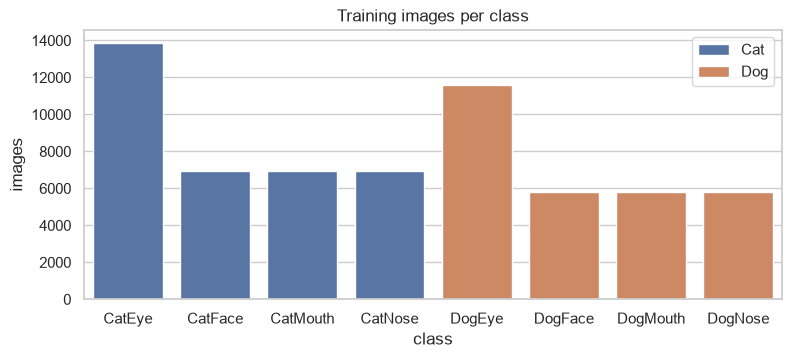

In [5]:
counts = train["class"].value_counts().reindex(CLASSES)
table = pd.DataFrame({"count": counts, "share %": 100 * counts / counts.sum()})
display(table)

for sp in ["Cat", "Dog"]:
    c = counts.filter(like=sp)
    print(f"{sp}: Eye/Face = {c[sp + 'Eye'] / c[sp + 'Face']:.3f}, Face = Nose = Mouth: "
          f"{c[sp + 'Face'] == c[sp + 'Nose'] == c[sp + 'Mouth']}, implied photos = {c[sp + 'Face']}")
print("test images:", len(test), "| divisible by 5:", len(test) % 5 == 0)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(x=counts.index, y=counts.values, hue=[c[:3] for c in counts.index], ax=ax)
ax.set_title("Training images per class")
ax.set_ylabel("images")
savefig("01_class_counts")
plt.show()

> **Observations (to be written by me):**

## 2. File format

`get_image_meta` opens every file once and records: byte size, MD5 hash, JPEG format / colour mode, EXIF presence,
progressive flag, a hash of the JPEG quantisation tables, width / height, mean R/G/B, brightness (mean grey),
contrast (std of grey), saturation (mean HSV S), sharpness (variance of the Laplacian), a greyscale flag and a 64-bit
difference hash (dHash, for near duplicates). See `src/data.py::scan_image`.

In [6]:
meta_tr = get_image_meta("train", N_JOBS)
meta_te = get_image_meta("test", N_JOBS)
meta_tr["split"], meta_te["split"] = "train", "test"
meta = pd.concat([meta_tr, meta_te], ignore_index=True)
meta["short"] = meta[["w", "h"]].min(axis=1)
meta["aspect"] = meta["w"] / meta["h"]
meta_tr, meta_te = meta[meta.split == "train"].copy(), meta[meta.split == "test"].copy()
print(meta.shape)

(93103, 27)


In [7]:
fmt = meta.groupby("split").agg(
    files=("path", "size"), readable=("ok", "sum"), formats=("format", lambda s: dict(s.value_counts())),
    modes=("mode", lambda s: dict(s.value_counts())), with_exif=("exif", "sum"), progressive=("progressive", "sum"),
    quant_table_sets=("qtables", "nunique"), total_MB=("bytes", lambda s: s.sum() / 1e6))
display(fmt.T)
print("quantisation-table hashes per split:", {k: sorted(set(v)) for k, v in meta.groupby("split")["qtables"]})

split,test,train
files,29443,63660
readable,29443,63660
formats,{'JPEG': 29443},{'JPEG': 63660}
modes,{'RGB': 29443},{'RGB': 63660}
with_exif,0,0
progressive,0,0
quant_table_sets,1,1
total_MB,322.1859,691.6515


quantisation-table hashes per split: {'test': ['dac25073'], 'train': ['dac25073']}


> **Observations (to be written by me):**

## 3. Image sizes

In [8]:
q = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
size_table = meta.groupby("split")["short"].describe(percentiles=q).T
display(size_table.round(1))

small = pd.DataFrame({split: {f"short side < {t} px": int((g["short"] < t).sum()) for t in [8, 16, 32, 48]}
                      for split, g in meta.groupby("split")})
display(small)

split,test,train
count,29443.0,63660.0
mean,103.5,105.1
std,94.4,92.5
min,8.0,4.0
1%,20.0,20.0
5%,28.0,30.0
25%,49.0,50.0
50%,77.0,78.0
75%,124.0,126.0
95%,267.0,268.0


,test,train
short side < 8 px,0,9
short side < 16 px,31,190
short side < 32 px,2422,4130
short side < 48 px,6945,13986


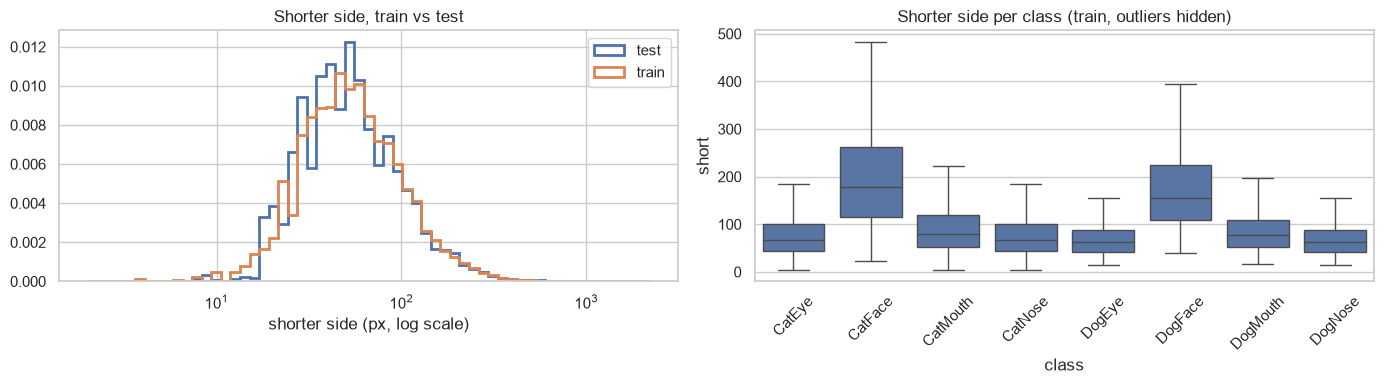

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.logspace(np.log10(2), np.log10(meta["short"].max()), 60)
for split, g in meta.groupby("split"):
    axes[0].hist(g["short"], bins=bins, density=True, histtype="step", lw=2, label=split)
axes[0].set_xscale("log")
axes[0].set_xlabel("shorter side (px, log scale)")
axes[0].set_title("Shorter side, train vs test")
axes[0].legend()
sns.boxplot(data=meta_tr, x="class", y="short", order=CLASSES, ax=axes[1], showfliers=False)
axes[1].set_title("Shorter side per class (train, outliers hidden)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
savefig("01_image_sizes")
plt.show()

> **Observations (to be written by me):**

## 4. Crop geometry per class (train)

Aspect ratio = width / height. "exact square" means width == height.

In [10]:
def aspect_profile(g):
    ar = g["aspect"]
    return pd.Series({
        "n": len(g), "median aspect": ar.median(), "exact square %": 100 * (g["w"] == g["h"]).mean(),
        "aspect 0.97-1.03 %": 100 * ar.between(0.97, 1.03).mean(),
        "aspect 1.30-1.40 %": 100 * ar.between(1.30, 1.40).mean(),
        "aspect 1.40-1.50 %": 100 * ar.between(1.40, 1.50).mean(),
        "aspect 0.6-1.0 %": 100 * ar.between(0.6, 1.0).mean(),
        "aspect p5": ar.quantile(0.05), "aspect p95": ar.quantile(0.95),
        "median short side": g["short"].median()})

display(meta_tr.groupby("class").apply(aspect_profile, include_groups=False).reindex(CLASSES).round(3))

,n,median aspect,exact square %,aspect 0.97-1.03 %,aspect 1.30-1.40 %,aspect 1.40-1.50 %,aspect 0.6-1.0 %,aspect p5,aspect p95,median short side
class,,,,,,,,,,
CatEye,13884.0,1.000,99.914,99.935,0.007,0.007,99.957,1.000,1.000,68.0
CatFace,6942.0,0.828,0.576,6.929,1.080,0.461,81.475,0.639,1.164,178.0
CatMouth,6942.0,1.419,0.000,0.000,9.882,95.030,0.000,1.400,1.455,80.0
CatNose,6942.0,1.000,98.920,99.092,0.029,0.043,98.934,1.000,1.000,68.0
DogEye,11580.0,1.000,99.940,99.974,0.000,0.000,99.991,1.000,1.000,62.0
DogFace,5790.0,1.000,61.710,95.889,0.000,0.000,80.259,0.989,1.012,155.0
DogMouth,5790.0,1.354,0.017,0.017,99.257,0.242,0.017,1.333,1.366,77.0
DogNose,5790.0,1.000,99.896,99.931,0.000,0.000,99.931,1.000,1.000,62.0


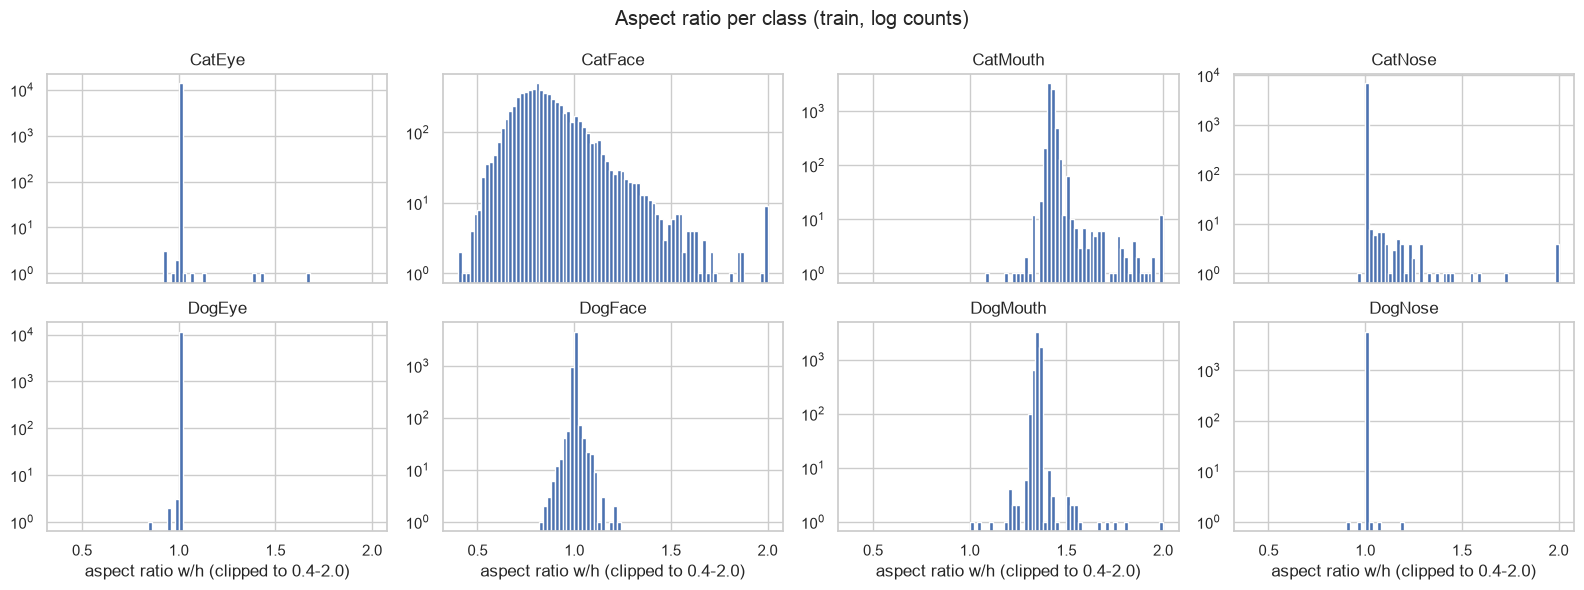

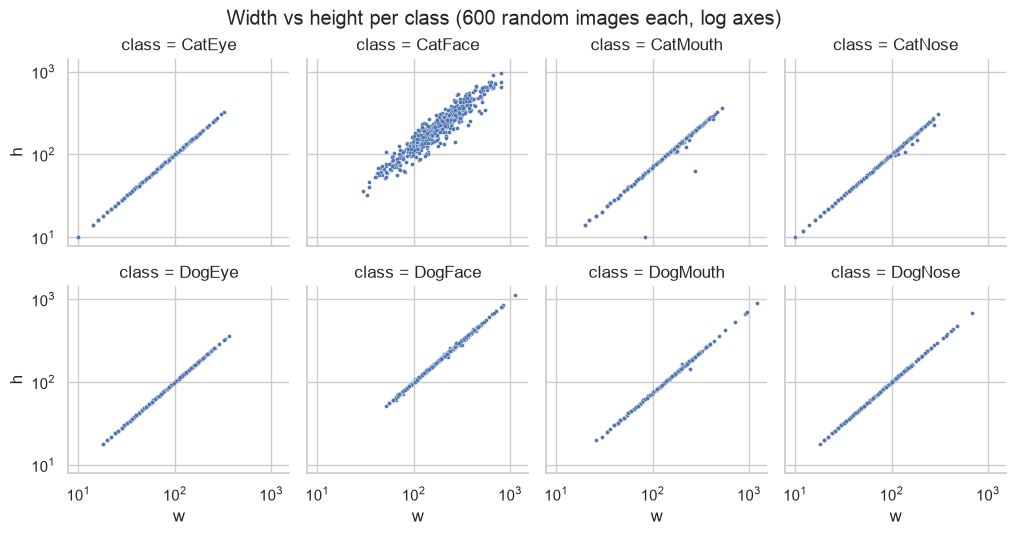

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for ax, c in zip(axes.flat, CLASSES):
    ax.hist(meta_tr.loc[meta_tr["class"] == c, "aspect"].clip(0.4, 2.0), bins=np.linspace(0.4, 2.0, 81))
    ax.set_title(c)
    ax.set_yscale("log")
for ax in axes[1]:
    ax.set_xlabel("aspect ratio w/h (clipped to 0.4-2.0)")
fig.suptitle("Aspect ratio per class (train, log counts)")
plt.tight_layout()
savefig("01_aspect_per_class")
plt.show()

sample = meta_tr.groupby("class").sample(600, random_state=SEED)
g = sns.relplot(data=sample, x="w", y="h", col="class", col_order=CLASSES, col_wrap=4, s=8, height=2.6)
g.set(xscale="log", yscale="log")
g.figure.suptitle("Width vs height per class (600 random images each, log axes)", y=1.02)
savefig("01_w_vs_h_per_class")
plt.show()

> **Observations (to be written by me):**

## 5. Train vs test geometry

The same summary function (`src/transforms.py::geometry_stats`) is used later to calibrate ShiftSim in notebook 02.

In [12]:
geo = pd.DataFrame({"train": geometry_stats(meta_tr["w"], meta_tr["h"]),
                    "test": geometry_stats(meta_te["w"], meta_te["h"])})
geo["test - train"] = geo["test"] - geo["train"]
display(geo.round(2))

,train,test,test - train
square %,65.52,32.85,-32.67
odd dimension %,18.91,55.01,36.10
both multiples of 10 %,13.81,21.24,7.43
aspect < 0.80 %,4.46,7.34,2.88
aspect 0.80-0.995 %,5.87,18.41,12.54
aspect 0.995-1.03 %,67.93,38.26,-29.67
aspect 1.03-1.30 %,1.52,16.97,15.45
aspect 1.30-1.50 %,19.95,14.93,-5.02
aspect > 1.50 %,0.27,4.09,3.82
short side p5,30.00,28.00,-2.00


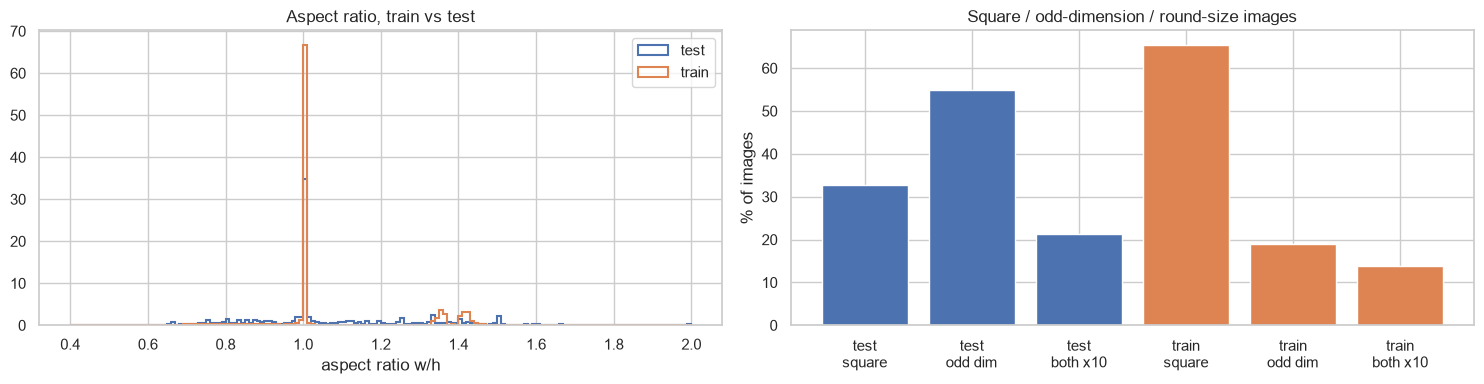

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
bins = np.linspace(0.4, 2.0, 161)
for split, g in meta.groupby("split"):
    axes[0].hist(g["aspect"].clip(0.4, 2.0), bins=bins, density=True, histtype="step", lw=1.5, label=split)
axes[0].set_xlabel("aspect ratio w/h")
axes[0].set_title("Aspect ratio, train vs test")
axes[0].legend()

for split, g in meta.groupby("split"):
    odd = ((g["w"] % 2) | (g["h"] % 2)).astype(bool)
    axes[1].bar([f"{split}\nsquare", f"{split}\nodd dim", f"{split}\nboth x10"],
                [100 * (g["w"] == g["h"]).mean(), 100 * odd.mean(),
                 100 * ((g["w"] % 10 == 0) & (g["h"] % 10 == 0)).mean()])
axes[1].set_ylabel("% of images")
axes[1].set_title("Square / odd-dimension / round-size images")
plt.tight_layout()
savefig("01_train_vs_test_geometry")
plt.show()

Most frequent exact sizes (width x height) in each split.

In [14]:
top = {split: (g["w"].astype(str) + "x" + g["h"].astype(str)).value_counts(normalize=True).head(20).mul(100)
       for split, g in meta.groupby("split")}
display(pd.concat({k: v.rename_axis("size").reset_index(name="%") for k, v in top.items()}, axis=1).round(2))

test        train      
       size     %   size     %
0     40x40  1.71  40x40  1.67
1     50x50  1.37  48x48  1.65
2     80x80  1.26  42x42  1.65
3     30x30  1.19  38x38  1.57
4     60x60  1.16  44x44  1.57
5     70x70  0.88  46x46  1.55
6     64x64  0.63  34x34  1.54
7     50x40  0.60  36x36  1.51
8     90x90  0.55  54x54  1.50
9     62x62  0.55  52x52  1.46
10    82x82  0.54  32x32  1.42
11    40x30  0.53  56x56  1.41
12    53x53  0.52  50x50  1.40
13    48x48  0.50  64x64  1.38
14  100x100  0.44  60x60  1.37
15    36x36  0.43  62x62  1.35
16    27x27  0.41  66x66  1.31
17    51x51  0.40  68x68  1.23
18    71x71  0.39  72x72  1.22
19    60x50  0.38  30x30  1.22

Sharpness of "round-size" images (both sides multiples of 10) compared with the other images of a similar size.
Sharpness depends on image size, so the comparison is made within shorter-side buckets.

median (other)  median (round)  size (other)  size (round)
split size bucket                                                             
test  (0, 32]               1999.0          2438.7          1813           819
      (32, 48]              1462.1          1845.2          3719           888
      (48, 64]              1205.5          1759.4          3631          1418
      (64, 80]              1245.9          1828.7          2565          1196
      (80, 100]             1181.3          1804.1          2479           699
      (100, 128]            1174.4          1842.8          3010           422
      (128, 10000]           914.9          1627.2          5973           811
train (0, 32]               2579.6          2276.9          4009          1209
      (32, 48]              1554.9          1495.8          8923          1062
      (48, 64]              1379.0          1320.6          7480          2099
      (64, 80]              1319.8          1467.1          6882          1365
      (80, 100]             1364.6          1287.0          6811          1010
      (100, 128]            1290.1          1010.8          6940           647
      (128, 10000]          1037.6           788.8         13824          1399

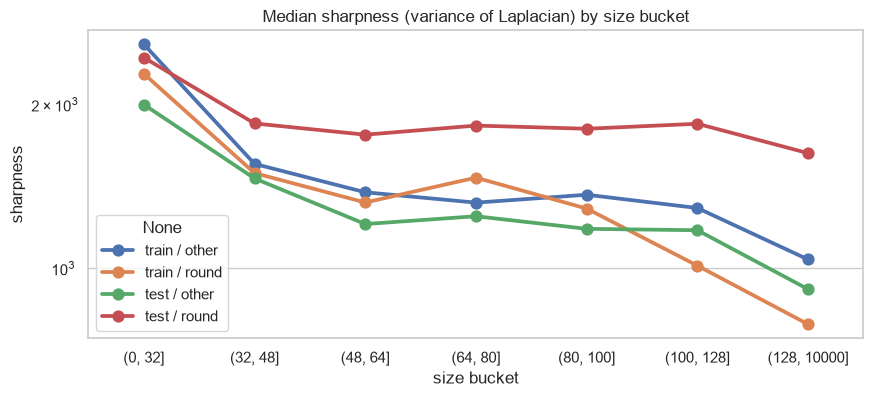

In [15]:
meta["round"] = (meta["w"] % 10 == 0) & (meta["h"] % 10 == 0)
meta["size bucket"] = pd.cut(meta["short"], [0, 32, 48, 64, 80, 100, 128, 10_000])
sharp = (meta.groupby(["split", "size bucket", "round"], observed=True)["sharpness"]
         .agg(["median", "size"]).unstack("round"))
sharp.columns = [f"{a} ({'round' if b else 'other'})" for a, b in sharp.columns]
display(sharp.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
sns.pointplot(data=meta, x="size bucket", y="sharpness", hue=meta["split"] + " / " + meta["round"].map({True: "round", False: "other"}),
              estimator=np.median, errorbar=None, ax=ax)
ax.set_yscale("log")
ax.set_title("Median sharpness (variance of Laplacian) by size bucket")
savefig("01_round_size_sharpness")
plt.show()

> **Observations (to be written by me):**

## 6. Train vs test colour and sharpness

KS statistic = maximum distance between the two cumulative distributions (0 = identical, 1 = disjoint).
With ~30k images per side even tiny differences get a small p-value, so the statistic itself is the
quantity to look at.

In [16]:
features = ["mean_r", "mean_g", "mean_b", "brightness", "contrast", "saturation", "sharpness", "bytes"]
rows = []
for f in features:
    a, b = meta_tr[f], meta_te[f]
    ks = stats.ks_2samp(a, b)
    rows.append({"feature": f, "train median": a.median(), "test median": b.median(),
                 "train mean": a.mean(), "test mean": b.mean(), "KS statistic": ks.statistic, "KS p-value": ks.pvalue})
display(pd.DataFrame(rows).set_index("feature").round(4))
print("greyscale %:", meta.groupby("split")["greyscale"].mean().mul(100).round(2).to_dict())

,train median,test median,train mean,test mean,KS statistic,KS p-value
feature,,,,,,
mean_r,123.7617,123.7061,122.7977,122.7716,0.0051,0.6798
mean_g,108.4842,108.8304,109.5114,109.6874,0.0056,0.5578
mean_b,95.3340,95.3294,98.5685,98.6980,0.0081,0.1420
brightness,109.3153,109.6051,110.2925,110.3857,0.0059,0.4756
contrast,47.9775,48.1969,48.7272,48.8502,0.0096,0.0476
saturation,62.0143,62.0024,70.0100,70.1683,0.0065,0.3662
sharpness,1366.1951,1344.6268,2450.8454,2429.2289,0.0071,0.2569
bytes,4333.5000,4211.0000,10864.7738,10942.6991,0.0131,0.0020


greyscale %: {'test': 1.64, 'train': 1.79}


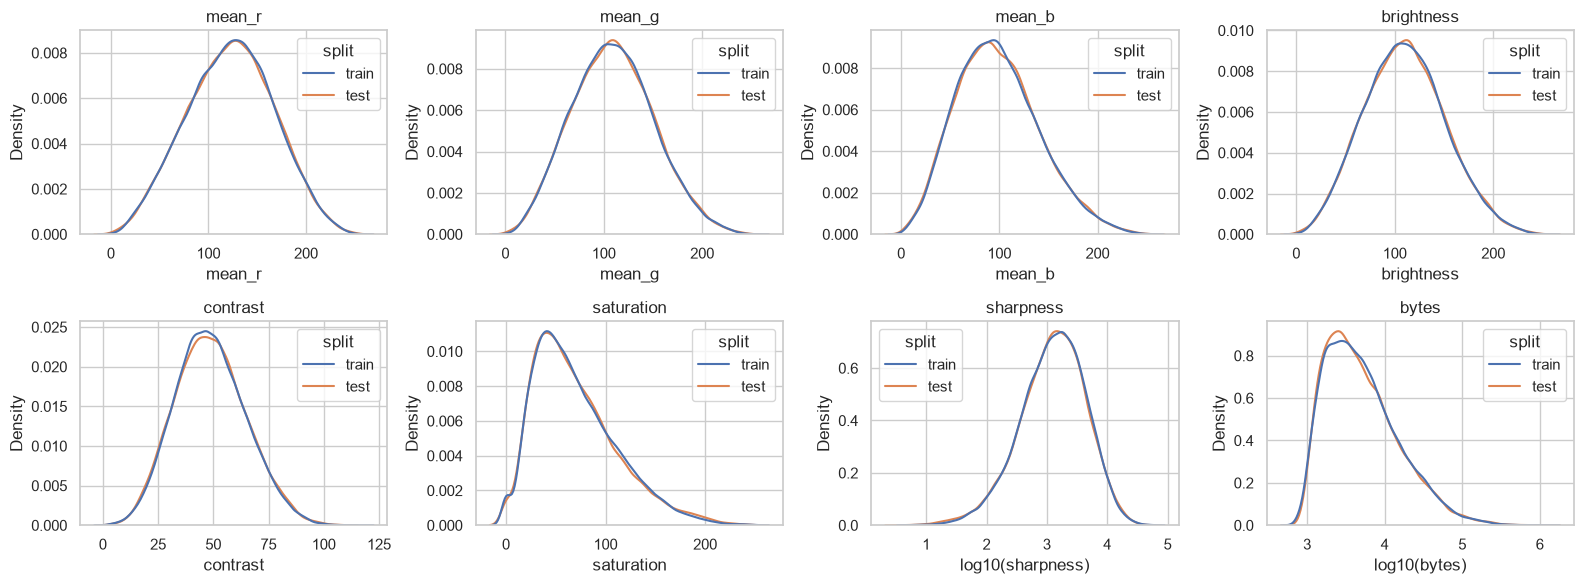

,greyscale %,brightness,saturation,sharpness
class,,,,
CatEye,3.03,105.93,63.99,2152.97
CatFace,3.11,110.32,65.14,1898.97
CatMouth,3.39,126.17,54.55,1837.79
CatNose,3.43,127.97,54.36,1398.19
DogEye,0.19,104.83,63.53,917.94
DogFace,0.07,106.69,67.33,921.93
DogMouth,0.05,101.64,65.43,1018.17
DogNose,0.07,100.79,59.52,1096.90


In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, f in zip(axes.flat, features):
    data = meta[[f, "split"]].copy()
    if f in ("sharpness", "bytes"):
        data[f] = np.log10(data[f] + 1)
        ax.set_xlabel(f"log10({f})")
    sns.kdeplot(data=data, x=f, hue="split", common_norm=False, ax=ax)
    ax.set_title(f)
plt.tight_layout()
savefig("01_colour_train_vs_test")
plt.show()

display(meta_tr.groupby("class")[["greyscale", "brightness", "saturation", "sharpness"]]
        .agg({"greyscale": lambda s: 100 * s.mean(), "brightness": "median", "saturation": "median",
              "sharpness": "median"}).reindex(CLASSES).round(2).rename(columns={"greyscale": "greyscale %"}))

> **Observations (to be written by me):**

## 7. Duplicates

Exact duplicates share the MD5 hash of the file bytes. Near duplicates share the 64-bit dHash
(a hash of the 9x8 greyscale thumbnail), so they look alike after resizing. Very small or flat images can share a
dHash without being related, so the near-duplicate counts are reported with the size of the largest group.

In [18]:
def dup_summary(df, col):
    g = df.groupby(col)
    sizes = g.size()
    out = {"groups with >1 image": int((sizes > 1).sum()), "images in such groups": int(sizes[sizes > 1].sum()),
           "largest group": int(sizes.max())}
    if "class" in df and df["class"].notna().all():
        n_classes = g["class"].nunique()
        out["groups with conflicting labels"] = int((n_classes > 1).sum())
    return out

dup = {}
for col in ["md5", "dhash"]:
    dup[f"train ({col})"] = dup_summary(meta_tr, col)
    dup[f"test ({col})"] = dup_summary(meta_te, col)
    dup[f"across train/test ({col})"] = {"shared hash values": len(set(meta_tr[col]) & set(meta_te[col]))}
display(pd.DataFrame(dup).T)

,groups with >1 image,images in such groups,largest group,groups with conflicting labels,shared hash values
train (md5),15.0,30.0,2.0,0.0,NaN
test (md5),62.0,124.0,2.0,NaN,NaN
across train/test (md5),NaN,NaN,NaN,NaN,0.0
train (dhash),43.0,86.0,2.0,0.0,NaN
test (dhash),65.0,130.0,2.0,NaN,NaN
across train/test (dhash),NaN,NaN,NaN,NaN,1.0


Examples of near-duplicate groups in train (same dHash, different files) with their labels.

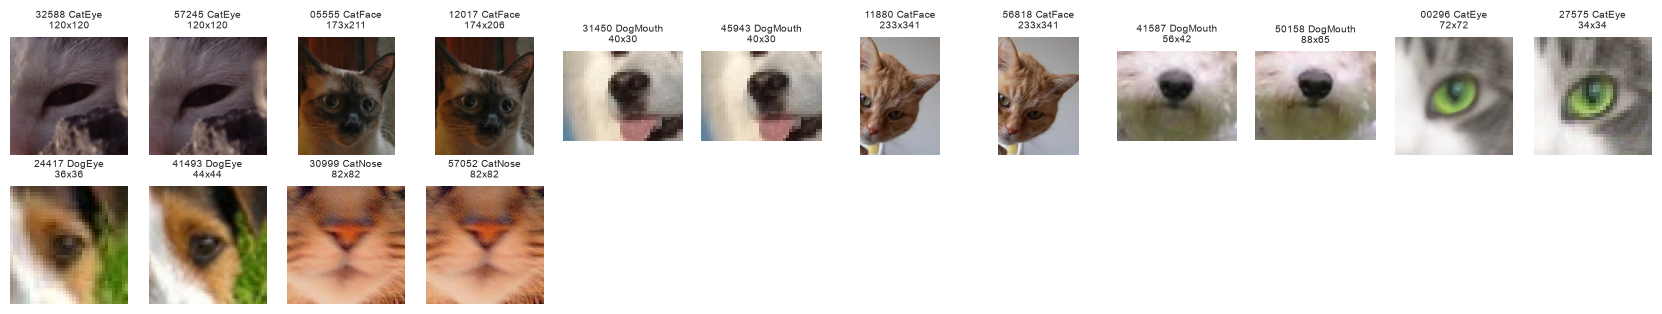

In [19]:
grp = meta_tr.groupby("dhash")
cand = [h for h, n in grp.size().items() if 2 <= n <= 4 and grp.get_group(h)["md5"].nunique() > 1]
pick = rng.choice(cand, size=min(8, len(cand)), replace=False)
imgs, titles = [], []
for h in pick:
    for _, r in grp.get_group(h).iterrows():
        imgs.append(r["path"])
        titles.append(f"{r['image_id']} {r['class']}\n{r['w']}x{r['h']}")
show_grid(imgs, titles, ncols=GRID_N, name="01_near_duplicates")

> **Observations (to be written by me):**

## 8. Order of the image ids

P(next id has the same class) = 0.1405;  expected if the order were random = 0.1411


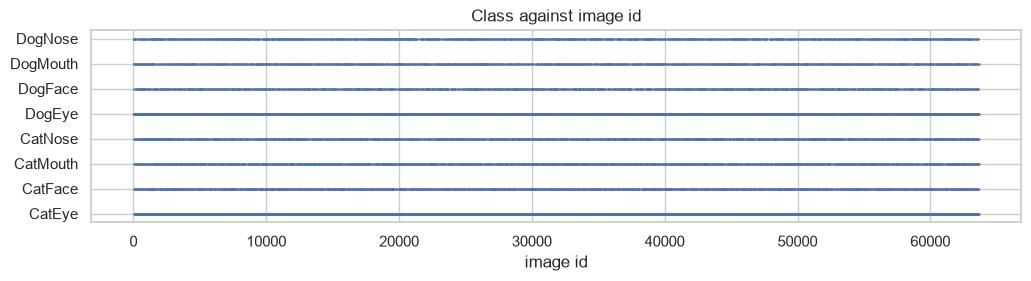

In [20]:
t = train.sort_values("image_id")
same_next = (t["class"].values[1:] == t["class"].values[:-1]).mean()
expected = ((counts / counts.sum()) ** 2).sum()
print(f"P(next id has the same class) = {same_next:.4f};  expected if the order were random = {expected:.4f}")

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.scatter(t["image_id"].astype(int), t["label"], s=0.3, alpha=0.3)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("image id")
ax.set_title("Class against image id")
savefig("01_id_order")
plt.show()

> **Observations (to be written by me):**

## 9. Example images

Each cell shows the image at its own aspect ratio (scaled to fit), titled with id / class / size.

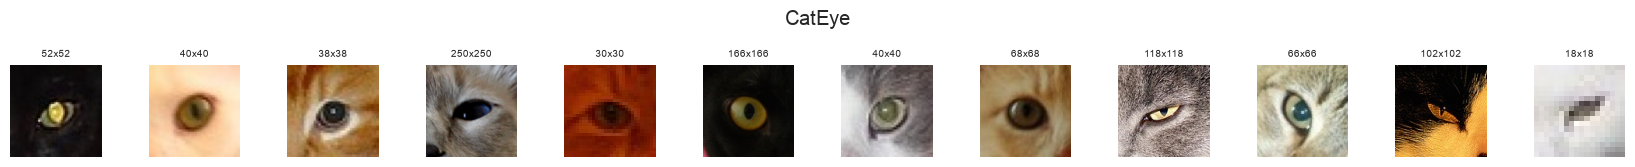

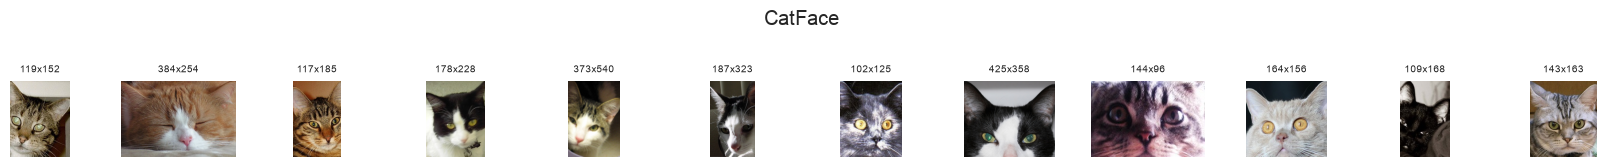

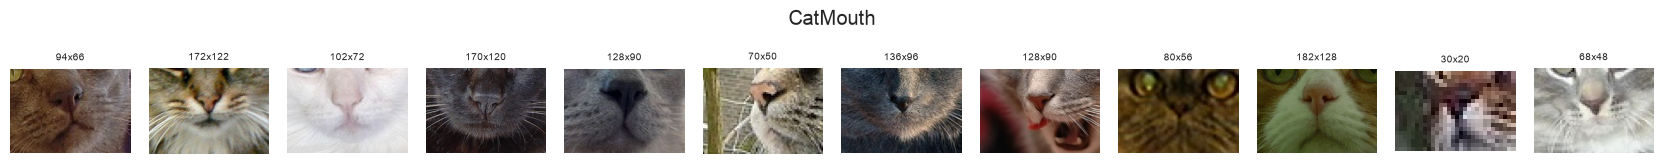

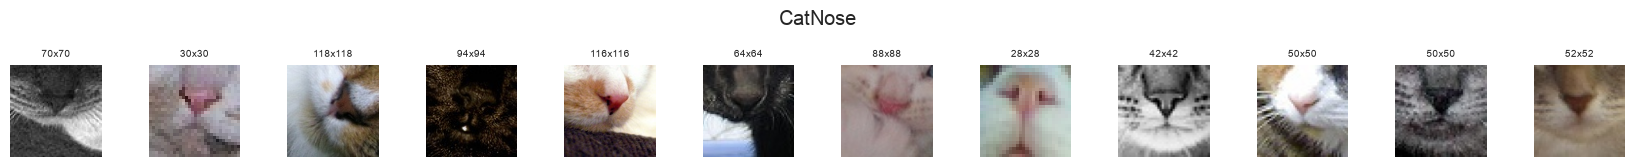

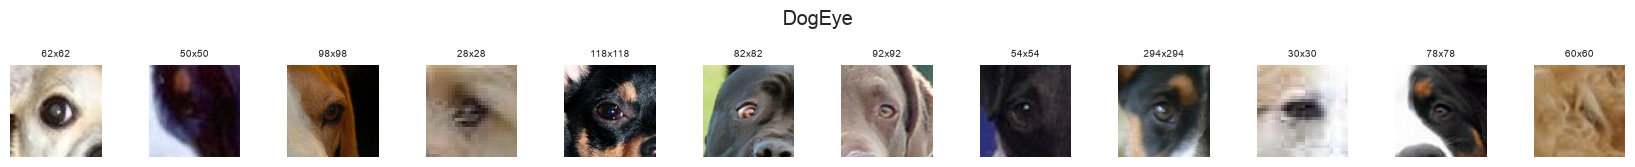

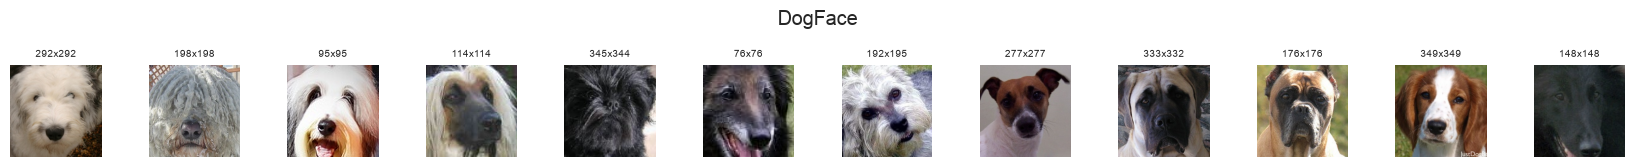

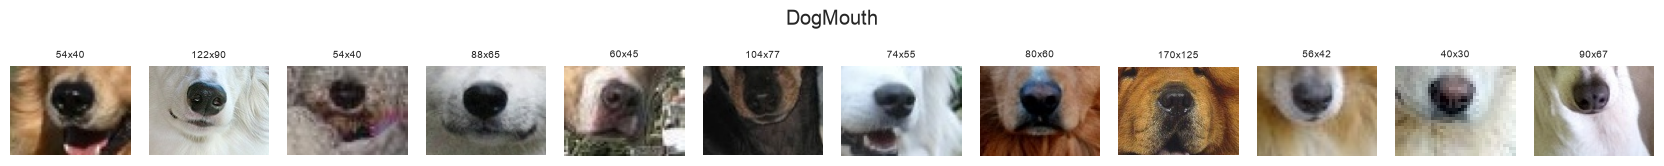

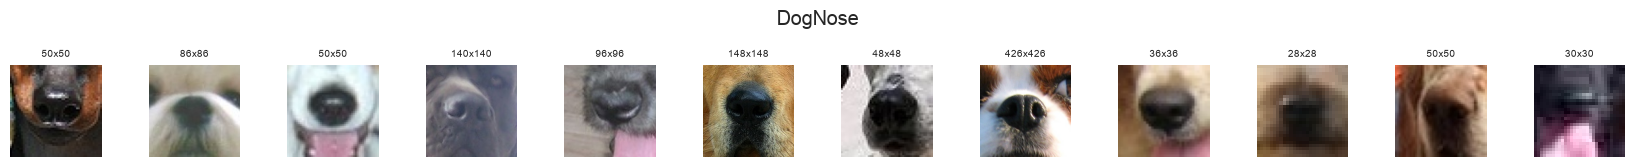

In [21]:
for c in CLASSES:
    s = meta_tr[meta_tr["class"] == c].sample(GRID_N, random_state=SEED)
    show_grid(s["path"].tolist(), [f"{w}x{h}" for w, h in zip(s["w"], s["h"])], ncols=GRID_N,
              suptitle=c, name=f"01_examples_{c}")

The smallest training images (shorter side < 16 px) and the most elongated ones (aspect > 3 or < 1/3).

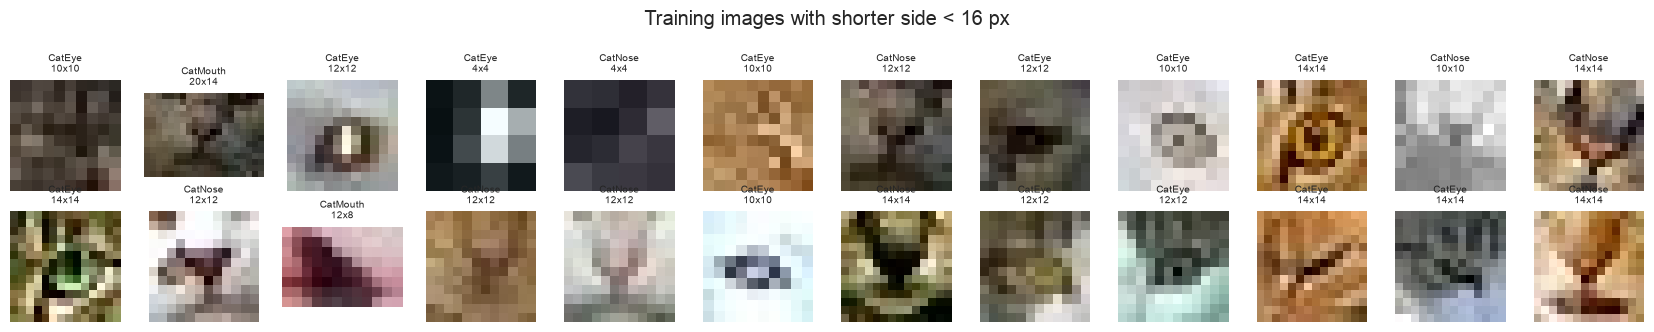

training images with aspect > 3 or < 1/3: 7


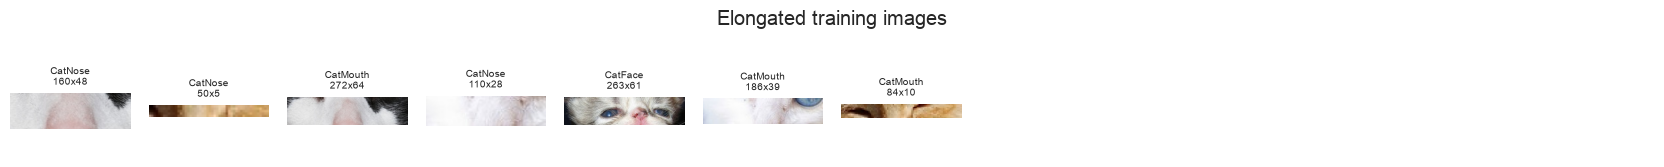

In [22]:
tiny = meta_tr[meta_tr["short"] < 16].sample(min(24, (meta_tr["short"] < 16).sum()), random_state=SEED)
show_grid(tiny["path"].tolist(), [f"{c}\n{w}x{h}" for c, w, h in zip(tiny["class"], tiny["w"], tiny["h"])],
          ncols=GRID_N, suptitle="Training images with shorter side < 16 px", name="01_tiny_train")

odd_shape = meta_tr[(meta_tr["aspect"] > 3) | (meta_tr["aspect"] < 1 / 3)]
print("training images with aspect > 3 or < 1/3:", len(odd_shape))
if len(odd_shape):
    s = odd_shape.head(24)
    show_grid(s["path"].tolist(), [f"{c}\n{w}x{h}" for c, w, h in zip(s["class"], s["w"], s["h"])],
              ncols=GRID_N, suptitle="Elongated training images", name="01_elongated_train")

Random test images, then test images grouped by aspect-ratio band (unlabelled; used only to inspect framing).

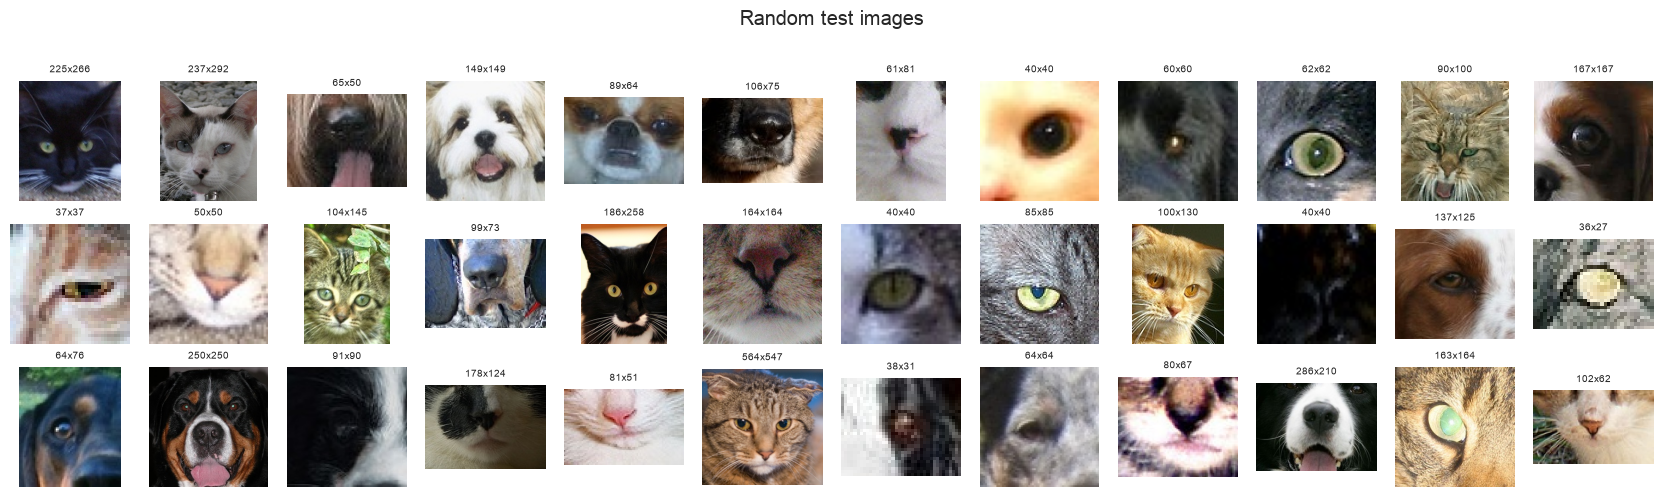

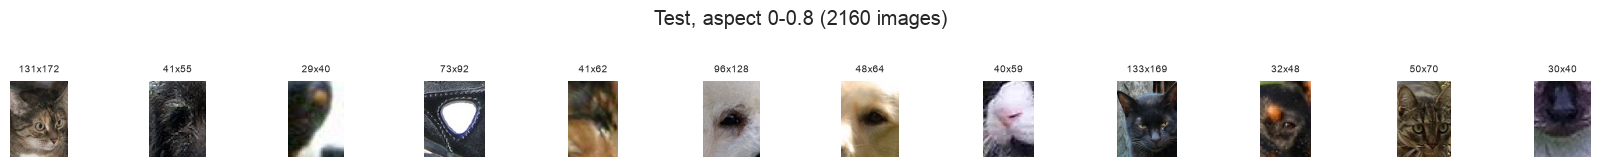

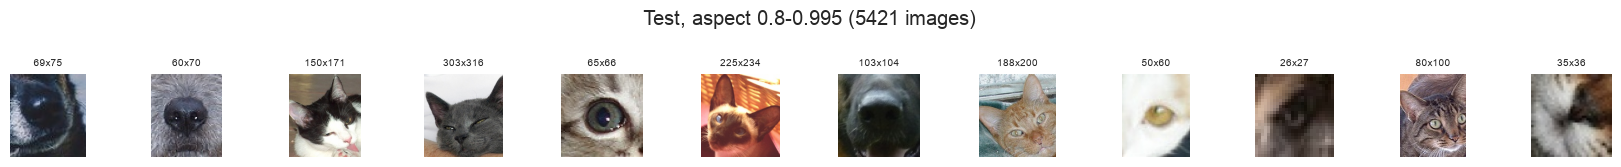

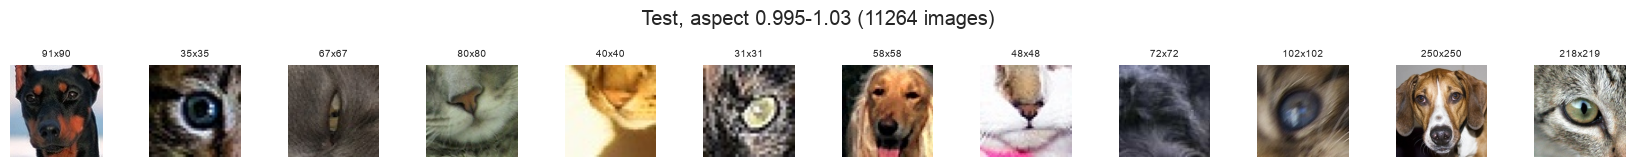

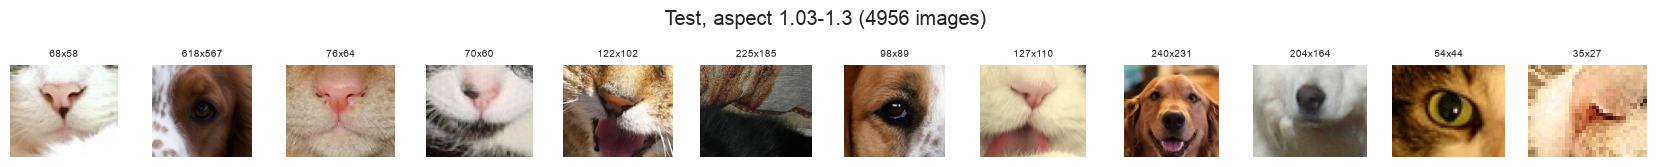

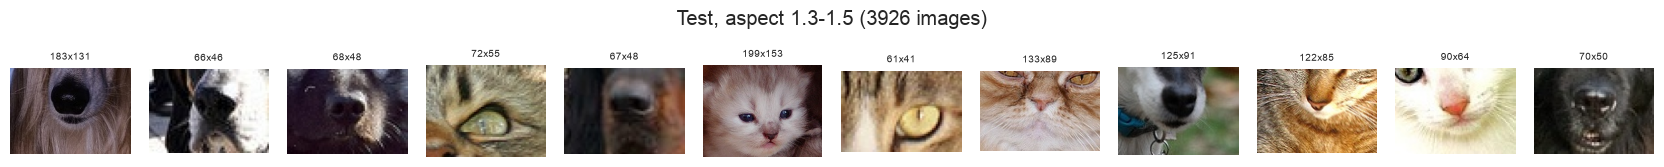

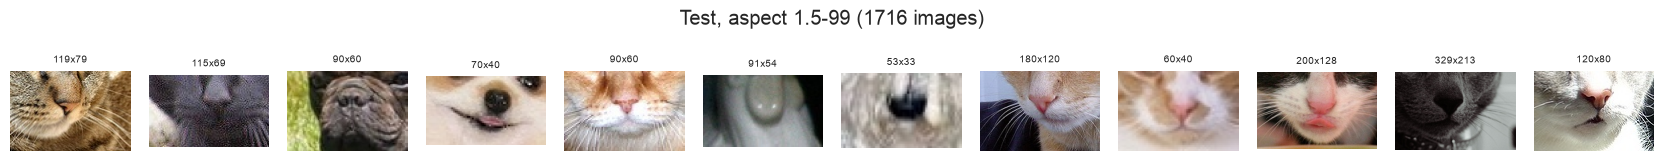

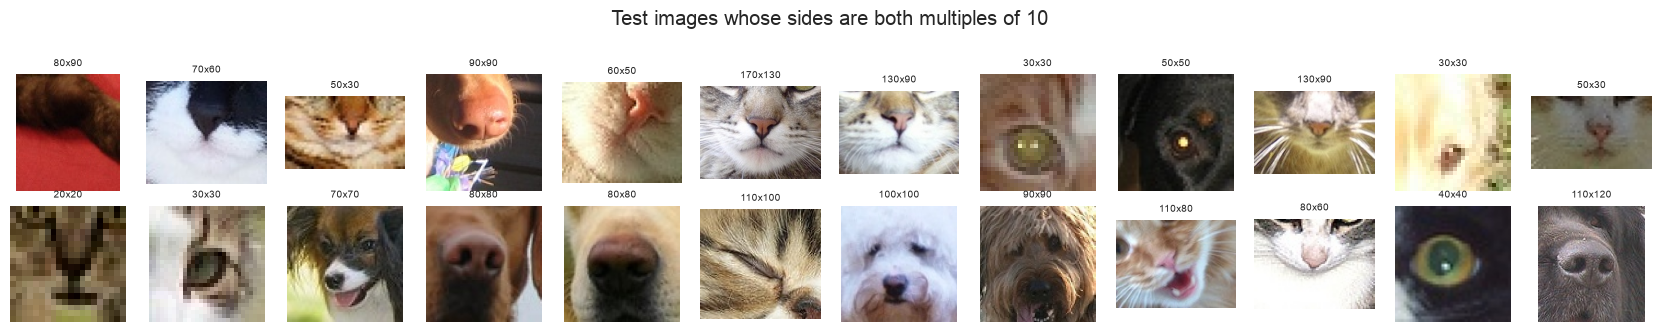

In [23]:
s = meta_te.sample(36, random_state=SEED)
show_grid(s["path"].tolist(), ncols=GRID_N, suptitle="Random test images", name="01_test_random")

bands = [(0, 0.8), (0.8, 0.995), (0.995, 1.03), (1.03, 1.3), (1.3, 1.5), (1.5, 99)]
for lo, hi in bands:
    sel = meta_te[(meta_te["aspect"] >= lo) & (meta_te["aspect"] < hi)]
    s = sel.sample(min(GRID_N, len(sel)), random_state=SEED)
    show_grid(s["path"].tolist(), ncols=GRID_N, suptitle=f"Test, aspect {lo}-{hi} ({len(sel)} images)",
              name=f"01_test_aspect_{lo}_{hi}")

s = meta_te[(meta_te["w"] % 10 == 0) & (meta_te["h"] % 10 == 0)]
s = s.sample(GRID_N * 2, random_state=SEED)
show_grid(s["path"].tolist(), ncols=GRID_N, suptitle="Test images whose sides are both multiples of 10",
          name="01_test_round_sizes")

> **Observations (to be written by me):**

## Summary tables for the report

The cell below collects the main numbers of this notebook into one table and saves it to `outputs/figures/01_summary.csv`.

In [24]:
summary = pd.concat({
    "class counts": counts.astype(float),
    "train vs test geometry (train)": geo["train"],
    "train vs test geometry (test)": geo["test"],
})
summary.to_csv(FIG_DIR / "01_summary.csv")
summary.to_frame("value").round(3)

value
class counts                   CatEye                  13884.000
                               CatFace                  6942.000
                               CatMouth                 6942.000
                               CatNose                  6942.000
                               DogEye                  11580.000
                               DogFace                  5790.000
                               DogMouth                 5790.000
                               DogNose                  5790.000
train vs test geometry (train) square %                   65.520
                               odd dimension %            18.910
                               both multiples of 10 %     13.809
                               aspect < 0.80 %             4.460
                               aspect 0.80-0.995 %         5.869
                               aspect 0.995-1.03 %        67.926
                               aspect 1.03-1.30 %          1.521
                               aspect 1.30-1.50 %         19.954
                               aspect > 1.50 %             0.270
                               short side p5              30.000
                               short side p50             78.000
                               short side p95            268.050
train vs test geometry (test)  square %                   32.850
                               odd dimension %            55.011
                               both multiples of 10 %     21.238
                               aspect < 0.80 %             7.336
                               aspect 0.80-0.995 %        18.412
                               aspect 0.995-1.03 %        38.257
                               aspect 1.03-1.30 %         16.972
                               aspect 1.30-1.50 %         14.931
                               aspect > 1.50 %             4.093
                               short side p5              28.000
                               short side p50             77.000
                               short side p95            267.000